# jaxsedfit: joint SED and spectrum fit of a Chimera

This notebook fits the broadband photometry and the optical spectrum of the *Chimera* from the first tutorial with one model. The Chimera is a real COSMOS galaxy with a scaled SDSS quasar added, to both its photometry and its spectrum: the spectrum is the galaxy's DESI DR1 spectrum plus the quasar's SDSS spectrum. The true stellar mass, and the true host and quasar spectra, are therefore known. It covers

1. loading the photometry and the spectrum;
2. adding the spectrum to the `FitConfig` of the first tutorial;
3. running the fit and comparing it to the truth;
4. comparing the recovered host and quasar spectra to the true ones;
5. comparing the stellar mass with a photometry-only fit.

You need the DSPS SSP template file `tempdata.h5` in the repository root (see the installation instructions).

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from astropy.table import Table

from jaxsedfit import (
    AGNConfig,
    FilterSet,
    FitConfig,
    GalaxyConfig,
    InferenceConfig,
    JAXSEDFit,
    LikelihoodConfig,
    Observation,
    PhotometryData,
    PriorConfig,
    SpectroscopyData,
    load_filter_curves,
)

/Users/colinburke/miniforge3/envs/jaxcpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

The photometry is in mJy, as in the first tutorial. The spectrum is on an observed-frame vacuum wavelength grid in Å, with flux densities in mJy; `flux_gal` and `flux_qso` are the true host and quasar spectra (`flux = flux_gal + flux_qso`). `flux_err` is infinite where either spectrum is missing, and those pixels are masked.

143317.88+173537.6_891438_0.03: z = 0.482, true log M* = 11.25, true log L_bol,AGN = 43.94
3286 of 3286 spectral pixels usable, resolving power 1500


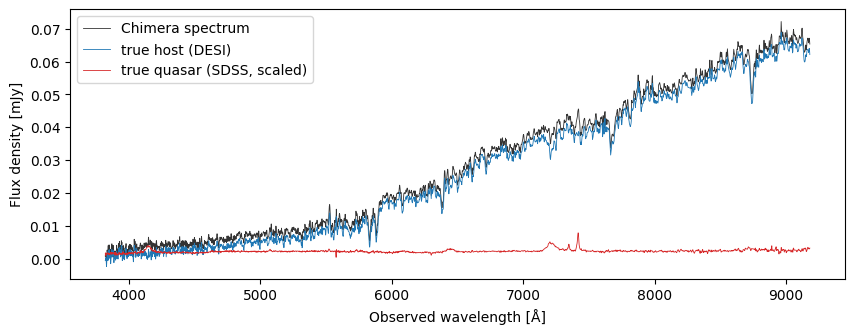

In [2]:
phot = Table.read("data/chimera_cosmos_891438.ecsv")
spec = Table.read("data/chimera_cosmos_891438_spectrum.ecsv")
z = phot.meta["redshift"]
truth_log_mass = phot.meta["log_stellar_mass_truth"]
truth_log_lbol = phot.meta["log_lbol_agn_truth"]
print(f"{phot.meta['object_id']}: z = {z:.3f}, true log M* = {truth_log_mass:.2f}, true log L_bol,AGN = {truth_log_lbol:.2f}")

wave = np.asarray(spec["wave_obs"], dtype=float)
good = np.isfinite(spec["flux_err"]) & (spec["flux_err"] > 0)
print(f"{good.sum()} of {len(spec)} spectral pixels usable, resolving power {spec.meta['resolving_power']:.0f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(wave, spec["flux"], color="0.2", lw=0.6, label="Chimera spectrum")
ax.plot(wave, spec["flux_gal"], color="C0", lw=0.6, label="true host (DESI)")
ax.plot(wave, spec["flux_qso"], color="C3", lw=0.6, label="true quasar (SDSS, scaled)")
ax.set(xlabel="Observed wavelength [Å]", ylabel="Flux density [mJy]")
ax.legend();

## 2. Configure the joint fit

The configuration is the first tutorial's, with these additions:

- `galaxy.fit_host_kinematics=True`: fit the host's stellar velocity dispersion and velocity offset. A massive galaxy has a dispersion of a few hundred km/s, which the spectrum resolves; without it the host model cannot match the absorption lines, and the AGN components absorb the misfit;
- `galaxy.host_sfh_model="delayed_burst"`: add a recent burst to the delayed-$\tau$ star-formation history, so the host continuum shape is flexible enough for a real galaxy spectrum;
- `spectroscopy`: a `SpectroscopyData` with the spectrum, its keep-mask and its resolving power, which sets the instrumental broadening;
- `agn.fit_lines` and `agn.fit_feii`: the quasar's broad and narrow emission lines and Fe II, which the spectrum resolves;
- `likelihood.fit_spectrum_scale=False`: the Chimera spectra are scaled to the photometry of each component, so no gray scale between the spectrum and the photometry is fitted. For real data, where the spectrum's aperture and calibration differ from the photometry's, leave it on.

The host stellar population and the AGN continuum are shared between the photometry and the spectrum.

With about 3,300 spectral pixels, NUTS takes much longer than for photometry alone, so this example uses `method="laplace"`: the MAP, then a Gaussian approximation with the inverse Hessian as covariance. That is also how the Chimera validation fits spectra. Use `"map+nuts"` for posteriors that do not rely on the Gaussian approximation.

In [3]:
config = FitConfig(
    observation=Observation(object_id=phot.meta["object_id"], redshift=z, redshift_mode="fixed"),
    photometry=PhotometryData(
        filter_names=list(phot["filter_name"]),
        fluxes=list(phot["flux_mjy"]),
        errors=list(phot["flux_err_mjy"]),
    ),
    filters=FilterSet(curves=load_filter_curves(list(phot["filter_name"]))),
    spectroscopy=SpectroscopyData(
        wave_obs=wave,
        fluxes=np.where(good, spec["flux"], 0.0),
        errors=np.where(good, spec["flux_err"], 1.0),
        mask=good,
        resolving_power=spec.meta["resolving_power"],
    ),
    galaxy=GalaxyConfig(dsps_ssp_fn="../tempdata.h5", fit_host_kinematics=True, host_sfh_model="delayed_burst"),
    agn=AGNConfig(agn_type=1, fit_lines=True, fit_feii=True),
    likelihood=LikelihoodConfig(use_local_line_photometry=True, fit_spectrum_scale=False),
    inference=InferenceConfig(method="laplace", map_steps=600, learning_rate=1e-2, num_samples=400),
    prior_config=PriorConfig(stellar_mass=dist.StudentT(df=5.0, loc=10.0, scale=2.0)),
)

## 3. Fit and compare to the truth

The AGN bolometric luminosity is a derived quantity, so it comes from `predict()` rather than `result.samples`; `log_agn_bol_luminosity_fit` is in W.

In [4]:
fitter = JAXSEDFit(config)
result = fitter.fit(progress_bar=False)
pred = fitter.predict()


def summary(name, values, truth):
    lo, mid, hi = np.percentile(values, [16, 50, 84])
    print(f"{name}: {mid:.2f} (+{hi - mid:.2f}/-{mid - lo:.2f}), truth {truth:.2f}, residual {mid - truth:+.2f} dex")


summary("log M*", result.samples["log_stellar_mass"], truth_log_mass)
# log_agn_bol_luminosity_fit is in W; add 7 for erg/s.
summary("log L_bol,AGN [erg/s]", pred["log_agn_bol_luminosity_fit"] + 7.0, truth_log_lbol)

log M*: 11.19 (+0.01/-0.01), truth 11.25, residual -0.06 dex
log L_bol,AGN [erg/s]: 44.41 (+0.14/-0.14), truth 43.94, residual +0.48 dex


## 4. Spectrum and SED

`plot_spectrum` draws the spectrum in the rest frame with the model components and the normalized residuals; `plot_sed` draws the photometry with the full SED model.

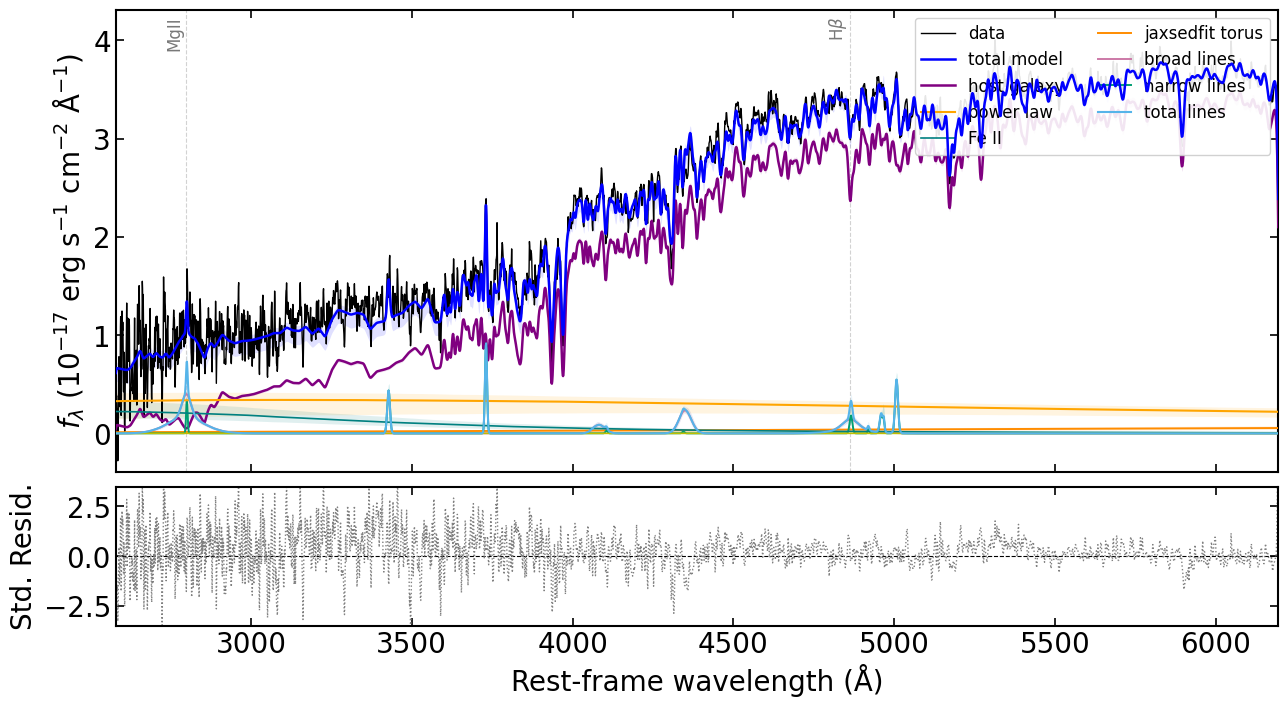

In [5]:
fitter.plot_spectrum(show_plot=True);

/Users/colinburke/research/jaxsedfit-tutorials/src/jaxsedfit/plotting.py:1044: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


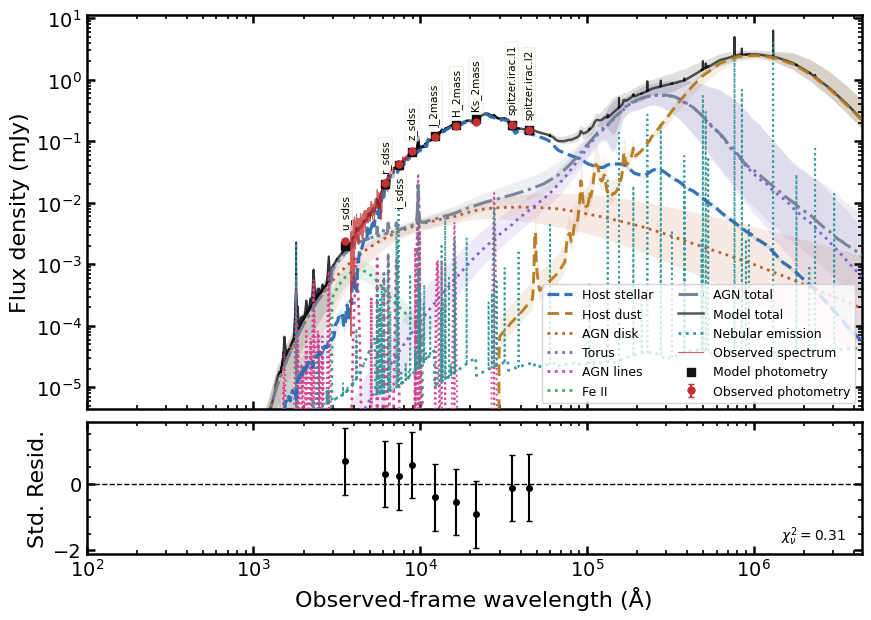

In [6]:
fitter.plot_sed(show=True);

Because the Chimera's host and quasar spectra are known separately, the decomposition itself can be checked. `predict()` returns the posterior model on the spectral pixels: `spec_host_model_fluxes` is the host, and the rest of `pred_spectrum_fluxes` is the AGN (continuum, lines, Fe II and Balmer continuum). The lines show posterior medians.

Recovered / true flux over the spectrum: host 0.92, AGN 1.62


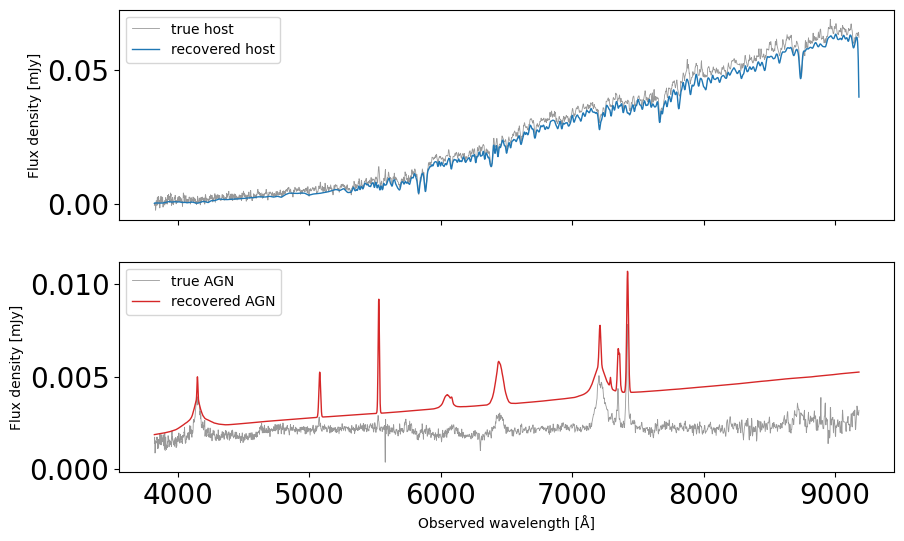

In [7]:
pix = np.asarray(pred["spec_wave_obs"][0])
total = np.median(pred["pred_spectrum_fluxes"], axis=0)
host = np.median(pred["spec_host_model_fluxes"], axis=0)
agn = np.median(pred["pred_spectrum_fluxes"] - pred["spec_host_model_fluxes"], axis=0)
true_host = np.interp(pix, wave, spec["flux_gal"])
true_agn = np.interp(pix, wave, spec["flux_qso"])

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, model, truth, label, color in ((axes[0], host, true_host, "host", "C0"), (axes[1], agn, true_agn, "AGN", "C3")):
    ax.plot(pix, truth, color="0.6", lw=0.6, label=f"true {label}")
    ax.plot(pix, model, color=color, lw=1.0, label=f"recovered {label}")
    ax.set_ylabel("Flux density [mJy]")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Observed wavelength [Å]")
print(f"Recovered / true flux over the spectrum: host {host.sum() / true_host.sum():.2f}, AGN {agn.sum() / true_agn.sum():.2f}")

## 5. What the spectrum adds

Fitting the same configuration without the spectrum shows how much it constrains the stellar mass. The Laplace widths come from the curvature at the MAP, so compare them between the two fits rather than reading them as exact uncertainties.

log M* (photometry only): 11.10 (+0.13/-0.14), truth 11.25, residual -0.15 dex


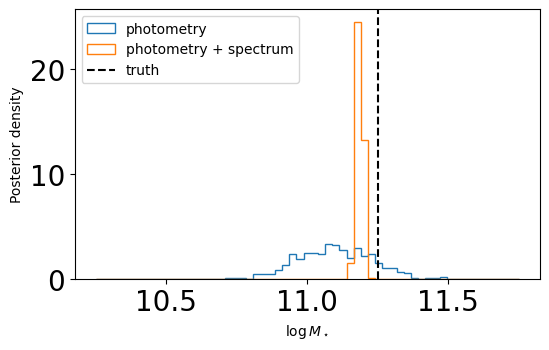

In [8]:
phot_config = copy.deepcopy(config)
phot_config.spectroscopy = None
phot_config.agn.fit_feii = False
phot_fitter = JAXSEDFit(phot_config)
phot_result = phot_fitter.fit(progress_bar=False)
summary("log M* (photometry only)", phot_result.samples["log_stellar_mass"], truth_log_mass)

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(truth_log_mass - 1.0, truth_log_mass + 0.5, 60)
ax.hist(phot_result.samples["log_stellar_mass"], bins=bins, density=True, histtype="step", lw=1.5, label="photometry")
ax.hist(result.samples["log_stellar_mass"], bins=bins, density=True, histtype="step", lw=1.5, label="photometry + spectrum")
ax.axvline(truth_log_mass, color="k", ls="--", label="truth")
ax.set(xlabel=r"$\log M_\star$", ylabel="Posterior density")
ax.legend();

## Next steps

- Use `method="map+nuts"` for a full posterior, and increase `map_steps` for science fits.
- For real spectra, keep `fit_spectrum_scale=True` and set `instrument` and `aperture_diameter_arcsec` in `SpectroscopyData`; the BandWagon joint-fit tutorial shows a complete example with an SDSS spectrum.
- Fit many objects at once with `jaxsedfit.fit_batch`.